# Loading the P(k) and CMB lensing emulators

Three emulators ship in `src/cmb_baryon_emu/lightweight_models/`. They were trained on
`scripts/generate_lss_training_data.py` output: one CAMB run per sample (HMcode-2020),
with the ACT DR6 lensing priors in `configs/emulator_config_lss_baryon.yaml`.

| model | predicts | inputs |
|---|---|---|
| `pk_lin` | linear P(k, z), dark-matter-only, (Mpc/h)^3 | 5 cosmological |
| `pk_nl_boost` | P_NL / P_lin, HMcode-2020 without feedback | 5 cosmological |
| `clpp` | raw C_L^phiphi with BCemu2025 feedback, L = 2..3000 | 5 cosmological + 8 baryon |

P(k) is given on k = 1e-5..50 h/Mpc (329 points) and z = 0..3 (31 points).
The last section compares against one CAMB run, which needs `camb` and BCemu
(the `cmb_baryon_venv` kernel has both).

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from cmb_baryon_emu import JaxNpzModel

plt.rcParams.update({"font.size": 11, "figure.dpi": 120})

## Load the models

In [2]:
pk_lin = JaxNpzModel.from_package("pk_lin")
pk_boost = JaxNpzModel.from_package("pk_nl_boost")
clpp = JaxNpzModel.from_package("clpp")

for name, m in [("pk_lin", pk_lin), ("pk_nl_boost", pk_boost), ("clpp", clpp)]:
    print(f"{name:12s}", m.parameter_names)
    print(f"{'':12s}", m.pk_axes)

k, z = pk_lin.pk_k, pk_lin.pk_z  # h/Mpc, redshift
L = np.arange(2, 3001)          # the clpp output multipoles
print("k:", k.shape, k[0], k[-1], " z:", z.shape, z[0], z[-1])

An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.


pk_lin       ['omega_cdm', 'omega_b', 'ln10As', 'n_s', 'h']
             {'spectrum': 'pk_lin', 'k_unit': 'h/Mpc', 'ratio_to': ''}
pk_nl_boost  ['omega_cdm', 'omega_b', 'ln10As', 'n_s', 'h']
             {'spectrum': 'pk_nl', 'k_unit': 'h/Mpc', 'ratio_to': 'pk_lin'}
clpp         ['omega_cdm', 'omega_b', 'ln10As', 'n_s', 'h', 'log10Mc', 'Theta_co', 'mu', 'delta', 'eta', 'deta', 'Nstar', 'fb']
             None
k: (329,) 1e-05 50.0  z: (31,) 0.0 3.0


## Parameters

`predict` takes a dict of scalars or arrays keyed by `parameter_names`. Extra keys are
ignored, so the P(k) models can be given the baryon parameters too. Two BCemu2025
settings are used below: a fiducial one and a strong-feedback one.

In [3]:
cosmo = dict(omega_cdm=0.120, omega_b=0.02233, ln10As=3.044, n_s=0.96, h=0.6736)

bcm_fid = dict(log10Mc=13.1, Theta_co=0.3, mu=1.0, delta=6.0, eta=0.10, deta=0.22,
               Nstar=0.028, fb=0.0486 / 0.306)
bcm_strong = dict(log10Mc=14.3, Theta_co=0.3, mu=0.5, delta=6.0, eta=0.2, deta=0.2,
                  Nstar=0.03, fb=0.20)

## Matter power spectrum

`predict_pk` returns (n, n_z, n_k). `pk_nl_boost` predicts the ratio to P_lin
(`pk_axes["ratio_to"]`), so P_NL is the product of the two models.

In [4]:
plin = pk_lin.predict_pk(cosmo)[0]
pnl = plin * pk_boost.predict_pk(cosmo)[0]
print(plin.shape)

(31, 329)


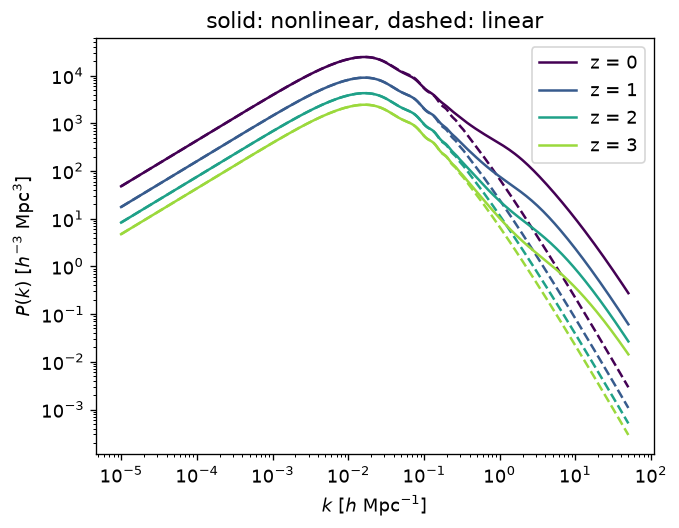

In [5]:
iz_plot = [0, 10, 20, 30]
colors = plt.cm.viridis(np.linspace(0, 0.85, len(iz_plot)))

fig, ax = plt.subplots(figsize=(6, 4.5))
for iz, c in zip(iz_plot, colors):
    ax.loglog(k, plin[iz], color=c, ls="--")
    ax.loglog(k, pnl[iz], color=c, label=f"z = {z[iz]:.0f}")
ax.set_xlabel(r"$k$ [$h$ Mpc$^{-1}$]")
ax.set_ylabel(r"$P(k)$ [$h^{-3}$ Mpc$^3$]")
ax.set_title("solid: nonlinear, dashed: linear")
ax.legend()
plt.show()

## CMB lensing potential

In [6]:
cl_fid = clpp.predict({**cosmo, **bcm_fid})[0]
cl_strong = clpp.predict({**cosmo, **bcm_strong})[0]
norm = (L * (L + 1.0)) ** 2 / (2 * np.pi)

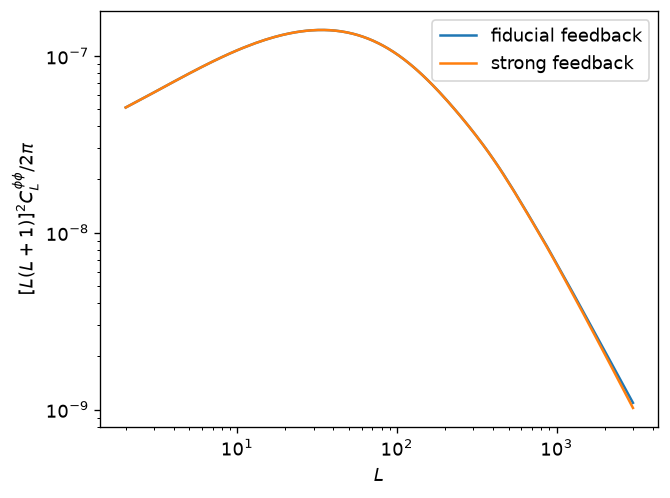

In [7]:
fig, ax = plt.subplots(figsize=(6, 4.5))
ax.loglog(L, norm * cl_fid, label="fiducial feedback")
ax.loglog(L, norm * cl_strong, label="strong feedback")
ax.set_xlabel(r"$L$")
ax.set_ylabel(r"$[L(L+1)]^2 C_L^{\phi\phi} / 2\pi$")
ax.legend()
plt.show()

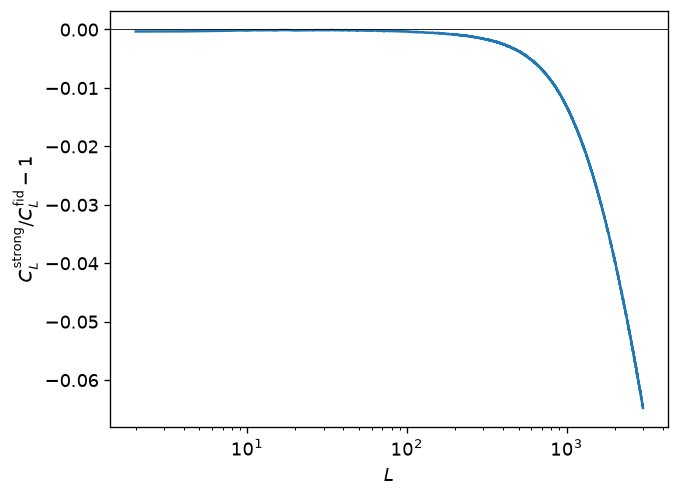

In [8]:
fig, ax = plt.subplots(figsize=(6, 4.5))
ax.semilogx(L, cl_strong / cl_fid - 1)
ax.axhline(0, color="k", lw=0.5)
ax.set_xlabel(r"$L$")
ax.set_ylabel(r"$C_L^{\rm strong} / C_L^{\rm fid} - 1$")
plt.show()

## Many parameter points at once

Pass arrays to predict a batch in one call.

In [9]:
rng = np.random.default_rng(0)
n = 1000
batch = {name: np.full(n, value) for name, value in cosmo.items()}
batch["omega_cdm"] = rng.uniform(0.10, 0.14, n)

pk_batch = pk_lin.predict_pk(batch) * pk_boost.predict_pk(batch)
print(pk_batch.shape)

(1000, 31, 329)


## Check against CAMB

`utils.predict_lss_spectra` is the function that made the training data (one CAMB
run, a few seconds).

In [10]:
from cmb_baryon_emu import utils

ref = utils.predict_lss_spectra({**cosmo, "tau": 0.0544}, bcm_fid)
assert np.allclose(ref["pk_k"], k) and np.allclose(ref["pk_z"], z)
assert np.array_equal(ref["ell"], L)

for name, emu, truth in [("pk_lin", plin, ref["pk_lin"]),
                         ("pk_nl", pnl, ref["pk_nl"]),
                         ("clpp", cl_fid, ref["clpp"])]:
    err = np.abs(emu / truth - 1)
    print(f"{name:7s} median |emu/CAMB - 1| = {np.median(err):.1e}, max = {err.max():.1e}")

/cluster/project/refregier/areeves/cmb_baryon_venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loading model weights:   0%|          | 0/21 [00:00<?, ?it/s]

Loading model weights:  10%|▉         | 2/21 [00:00<00:01, 13.99it/s]

Loading model weights:  19%|█▉        | 4/21 [00:00<00:01, 15.57it/s]

Loading model weights:  29%|██▊       | 6/21 [00:00<00:00, 15.96it/s]

...

Loading model weights:  71%|███████▏  | 15/21 [00:00<00:00, 16.76it/s]

Loading model weights:  86%|████████▌ | 18/21 [00:01<00:00, 17.83it/s]

Loading model weights:  95%|█████████▌| 20/21 [00:01<00:00, 16.57it/s]

Loading model weights: 100%|██████████| 21/21 [00:01<00:00, 16.80it/s]

pk_lin  median |emu/CAMB - 1| = 4.1e-05, max = 1.6e-03
pk_nl   median |emu/CAMB - 1| = 5.4e-05, max = 1.4e-03
clpp    median |emu/CAMB - 1| = 8.3e-04, max = 1.5e-03


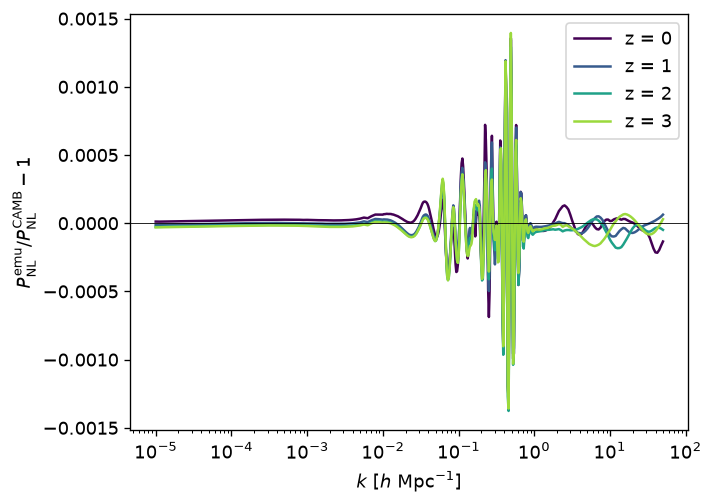

In [11]:
fig, ax = plt.subplots(figsize=(6, 4.5))
for iz, c in zip(iz_plot, colors):
    ax.semilogx(k, pnl[iz] / ref["pk_nl"][iz] - 1, color=c, label=f"z = {z[iz]:.0f}")
ax.axhline(0, color="k", lw=0.5)
ax.set_xlabel(r"$k$ [$h$ Mpc$^{-1}$]")
ax.set_ylabel(r"$P_{\rm NL}^{\rm emu} / P_{\rm NL}^{\rm CAMB} - 1$")
ax.legend()
plt.show()

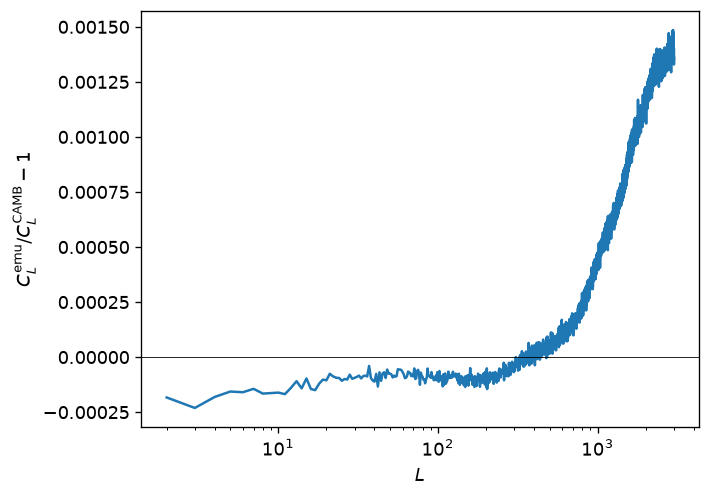

In [12]:
fig, ax = plt.subplots(figsize=(6, 4.5))
ax.semilogx(L, cl_fid / ref["clpp"] - 1)
ax.axhline(0, color="k", lw=0.5)
ax.set_xlabel(r"$L$")
ax.set_ylabel(r"$C_L^{\rm emu} / C_L^{\rm CAMB} - 1$")
plt.show()